# BazaarLens PK
## Data Visualization

This notebook presents key visual insights from Kaggle and Pakistan Bureau of Statistics (PBS) grocery price datasets.

In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [80]:
kaggle_df = pd.read_csv(r'../Datasets/cleaned/kaggle_grocery_cleaned.csv')
monthly_df = pd.read_csv(r'../Datasets/cleaned/pbs_monthly_cleaned.csv')
weekly_df = pd.read_csv(r'../Datasets/cleaned/pbs_weekly_cleaned.csv')

## 1. Kaggle Grocery Price Visualizations
Top 10 Most Expensive Grocery Items

In [81]:
kaggle_df.columns

Index(['City', 'Item', 'Brand', 'Price_per_Kg_Litre', 'Date_Collected',
       'Market_Source'],
      dtype='str')

In [82]:
Top10Items = kaggle_df.groupby('Item')['Price_per_Kg_Litre'].mean().sort_values(ascending=False)
Top10Items.head(10)

Item
Eggs (Dozen)     396.015000
Potato           377.582857
Tomato           349.203333
Atta (Flour)     348.625000
Cooking Oil      342.975600
Salt (Namak)     342.703810
Yogurt (Dahi)    333.225357
Masoor Dal       330.511739
Onion            329.338929
Chicken          327.342222
Name: Price_per_Kg_Litre, dtype: float64

In [83]:
Top_Expensive_Items = Top10Items.head(10).reset_index()

Top_Expensive_Items.columns = ['Items', 'Prices']

C:\Users\hp\AppData\Local\Temp\ipykernel_13648\2647140519.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


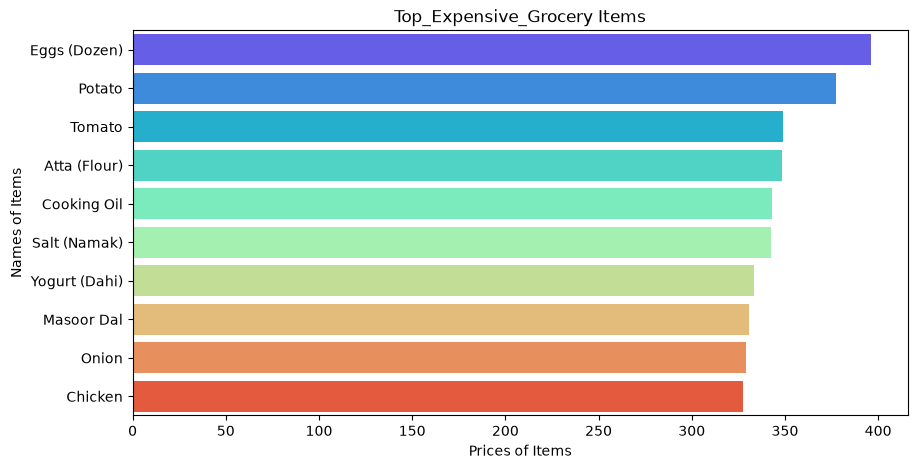

In [84]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=Top_Expensive_Items,
    x= 'Prices',
    y= 'Items',
    palette='rainbow'
)

plt.title('Top_Expensive_Grocery Items')
plt.xlabel('Prices of Items')
plt.ylabel('Names of Items')
plt.show()

In [85]:
Top_Expensive_Items.shape

(10, 2)

### Key Findings – Top 10 Most Expensive Grocery Items

1. Eggs (Dozen) has the highest average recorded price among all grocery items.
2. Potato ranks second, followed by Tomato.
3. Atta (Flour) and Cooking Oil are also among the top five most expensive items.
4. Moong Dal has the lowest average recorded price among the selected top 10 items.
5. The results show considerable variation in average prices across different grocery items.

**Note:** Eggs are priced per dozen, while most other items are priced per kg or litre. Therefore, these prices are not directly comparable on a standardized quantity basis.

Top 5 Most Expensive Cities

In [86]:
Top_5_Expensice_Cities = kaggle_df.groupby('City')['Price_per_Kg_Litre'].mean().sort_values(ascending=False).head(5)
Top_5_Expensice_Cities

City
Islamabad    350.330290
Lahore       345.648493
Peshawar     329.237206
Quetta       315.272609
Karachi      312.413662
Name: Price_per_Kg_Litre, dtype: float64

In [87]:
Top_Expensive_Cities = Top_5_Expensice_Cities.head(5).reset_index()
Top_Expensive_Cities.columns = ['Cities','Avg_Prices']

C:\Users\hp\AppData\Local\Temp\ipykernel_13648\3155008472.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


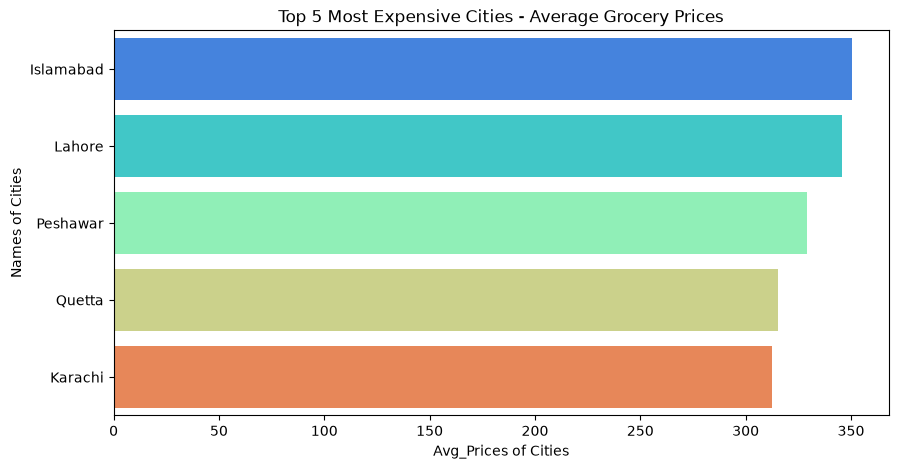

In [88]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=Top_Expensive_Cities,
    x= 'Avg_Prices',
    y= 'Cities',
    palette='rainbow'
)

plt.title('Top 5 Most Expensive Cities - Average Grocery Prices')
plt.xlabel('Avg_Prices of Cities')
plt.ylabel('Names of Cities')
plt.show()

In [89]:
Top_Expensive_Cities.shape

(5, 2)

### Key Findings – City-wise Grocery Prices

1. Islamabad has the highest average grocery price among the five selected cities.
2. Lahore ranks second, followed by Peshawar.
3. Karachi has the lowest average price among these five cities.
4. The results show variations in grocery prices across the selected cities.

## 2. PBS Monthly Price Visualizations
### City-wise Average Grocery Prices

In [90]:
pbs_monthly_df = pd.read_csv(r'../Datasets/cleaned/pbs_monthly_cleaned.csv')
pbs_monthly_df.columns

Index(['Serial_No', 'Item', 'Unit', 'Islamabad', 'Rawalpindi', 'Gujranwala',
       'Sialkot', 'Lahore', 'Faisalabad', 'Sargodha', 'Multan', 'Bahawalpur',
       'Karachi', 'Hyderabad', 'Sukkur', 'Larkana', 'Peshawar', 'Bannu',
       'Quetta', 'Khuzdar', 'Sep_2026_Avg', 'Aug_2026_Avg', 'Sep_2025_Avg',
       'Pct_Change_Monthly', 'Pct_Change_Yearly'],
      dtype='str')

In [91]:
city_columns = monthly_df.columns.drop([
    'Serial_No',
    'Item',
    'Unit',
    'Sep_2026_Avg',
    'Aug_2026_Avg',
    'Sep_2025_Avg',
    'Pct_Change_Monthly',
    'Pct_Change_Yearly'
])
city_columns

Index(['Islamabad', 'Rawalpindi', 'Gujranwala', 'Sialkot', 'Lahore',
       'Faisalabad', 'Sargodha', 'Multan', 'Bahawalpur', 'Karachi',
       'Hyderabad', 'Sukkur', 'Larkana', 'Peshawar', 'Bannu', 'Quetta',
       'Khuzdar'],
      dtype='str')

In [92]:
Monthly_City_Avg = monthly_df[city_columns].mean().sort_values(ascending=False)

Top5_Monthly_Cities = Monthly_City_Avg.head(5).reset_index()

Top5_Monthly_Cities.columns = ['City', 'Average_Price']

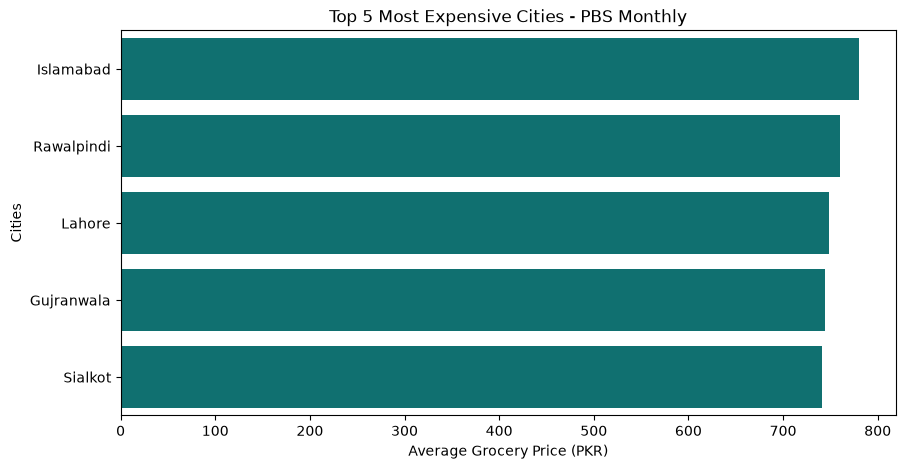

In [93]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=Top5_Monthly_Cities,
    x='Average_Price',
    y='City',
    color='teal'
)

plt.title('Top 5 Most Expensive Cities - PBS Monthly')
plt.xlabel('Average Grocery Price (PKR)')
plt.ylabel('Cities')
plt.show()

### Key Findings – PBS Monthly City-wise Prices

1. Islamabad has the highest average grocery price among the selected cities.
2. Rawalpindi ranks second in average grocery prices.
3. Lahore, Gujranwala, and Sialkot follow in the top five most expensive cities.
4. The results indicate differences in average grocery prices across the selected cities.

In [94]:
Top10_Monthly_Items = monthly_df.groupby('Item')['Sep_2026_Avg'].mean().sort_values(ascending=False).head(10)
Top10_Monthly_expensive_Items = Top10_Monthly_Items.head(10).reset_index()
Top10_Monthly_expensive_Items.columns = ['Items','Average_Price']

C:\Users\hp\AppData\Local\Temp\ipykernel_13648\4041828956.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


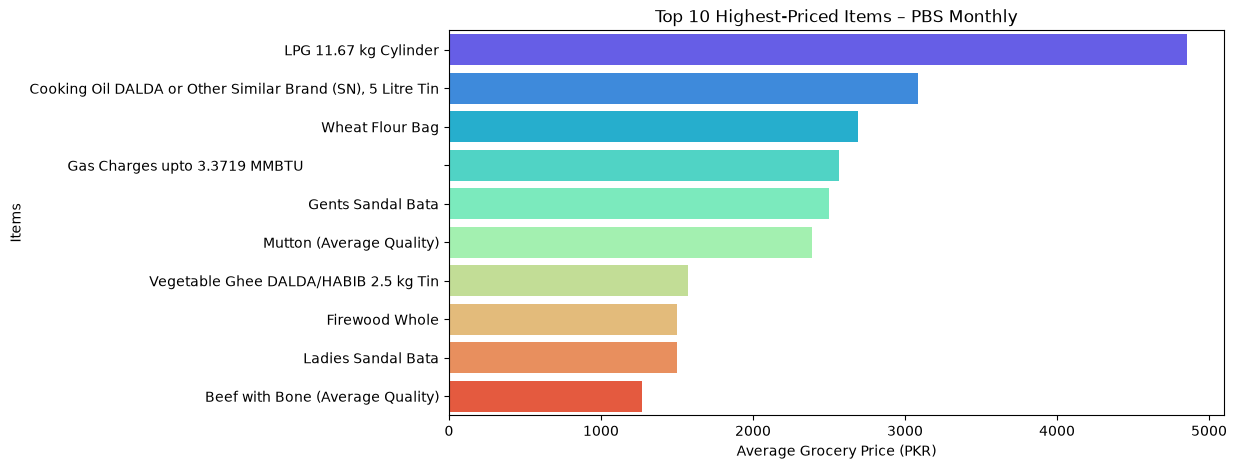

In [95]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=Top10_Monthly_expensive_Items,
    x='Average_Price',
    y='Items',
    palette= 'rainbow'
)

plt.title('Top 10 Highest-Priced Items – PBS Monthly')
plt.xlabel('Average Grocery Price (PKR)')
plt.ylabel('Items')
plt.show()

### Key Findings – PBS Monthly Top 10 Items

1. LPG 11.67 kg Cylinder has the highest average price among the selected items.
2. Cooking Oil DALDA (5 Litre Tin) ranks second, followed by Wheat Flour Bag.
3. Gas Charges, Gents Sandal, and Mutton also appear among the top five.
4. Beef with Bone has the lowest average price among the selected top 10 items.
5. The dataset includes household and non-food items as well as groceries, so it represents a broader price basket rather than groceries alone.

**Note:** Prices are based on the September 2026 average column (`Sep_2026_Avg`). Different items have different units, so their prices should not be directly compared without considering those units.

In [96]:
Top10_Monthly_Chnage = monthly_df.groupby('Item')['Pct_Change_Monthly'].mean().sort_values(ascending= False).head(10)
Top10_Monthly_Chnage_pct = Top10_Monthly_Chnage.reset_index()
Top10_Monthly_Chnage_pct.columns = ['Items','Chnage in Price per Month Percentage']

C:\Users\hp\AppData\Local\Temp\ipykernel_13648\2506491997.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


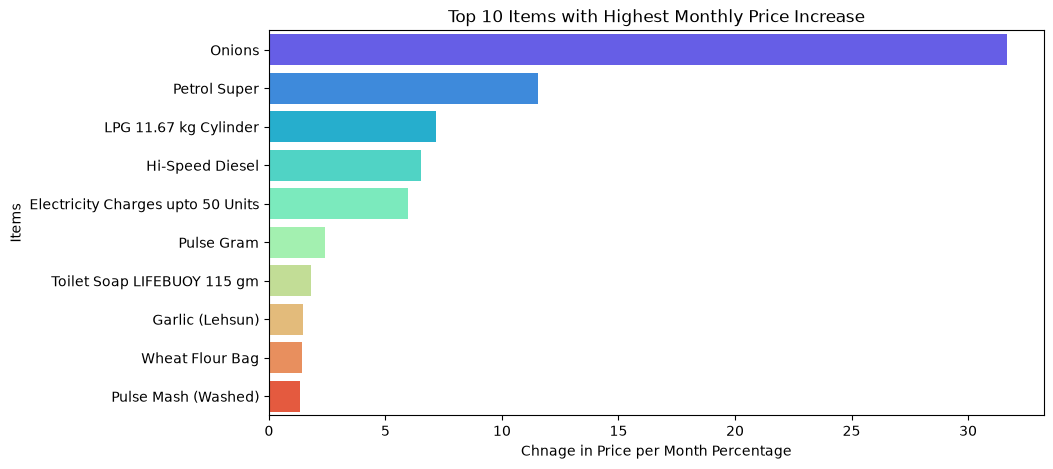

In [97]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=Top10_Monthly_Chnage_pct,
    x='Chnage in Price per Month Percentage',
    y='Items',
    palette= 'rainbow'
)

plt.title('Top 10 Items with Highest Monthly Price Increase')
plt.xlabel('Chnage in Price per Month Percentage')
plt.ylabel('Items')
plt.show()

In [98]:
Top10_Yearly_Chnage = monthly_df.groupby('Item')['Pct_Change_Yearly'].mean().sort_values(ascending= False).head(10)
Top10_Yearly_Chnage_pct = Top10_Yearly_Chnage.reset_index()
Top10_Yearly_Chnage_pct.columns = ['Items','Chnage in Price per Year Percentage']

C:\Users\hp\AppData\Local\Temp\ipykernel_13648\549756528.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


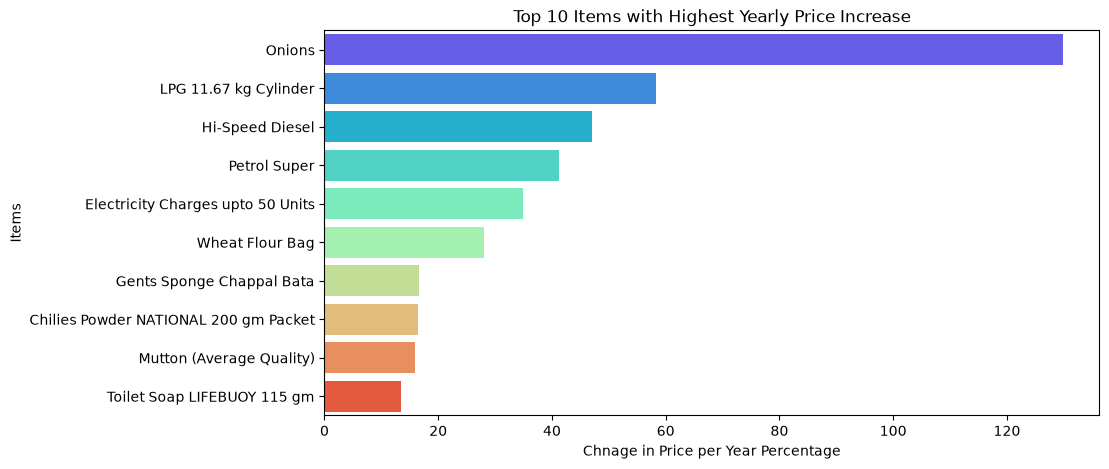

In [99]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=Top10_Yearly_Chnage_pct,
    x='Chnage in Price per Year Percentage',
    y='Items',
    palette= 'rainbow'
)

plt.title('Top 10 Items with Highest Yearly Price Increase')
plt.xlabel('Chnage in Price per Year Percentage')
plt.ylabel('Items')
plt.show()